# Experimento comparativo — algoritmos de clusterização dos municípios

**Projeto:** ENEM — Pará (PA)  
**Período:** 2009–2023  
**Objetivo:** verificar se algoritmos alternativos produzem perfis municipais substancialmente diferentes daqueles obtidos pelo K-Means no notebook Q8B.

## 1. Objetivo e estratégia do experimento

Este notebook é exclusivamente exploratório. Ele **não substitui nem altera** o notebook longitudinal principal. A comparação será realizada com três alternativas do Scikit-learn:

- **Agglomerative Clustering:** agrupamento hierárquico; serão testados 2 e 3 grupos, com ligação Ward.
- **Gaussian Mixture Model (GMM):** modelo probabilístico de mistura gaussiana; serão testados 2 e 3 componentes.
- **DBSCAN:** agrupamento por densidade, sem informar previamente o número de grupos; serão avaliadas combinações de `eps` e `min_samples`.

Como referência, será utilizada a classificação K-Means já produzida pelo notebook principal. A intenção é avaliar se as alternativas confirmam os perfis encontrados ou se mudam significativamente a composição dos grupos.

### Padronização e comparabilidade

Em cada edição, os cinco indicadores (`CH`, `CN`, `LC`, `MT` e `REDACAO`) serão padronizados novamente, exatamente como no procedimento anual do Q8B. Cada algoritmo receberá os mesmos 37 municípios da coorte balanceada, na mesma edição e com as mesmas cinco variáveis.

A comparação entre rótulos será feita com **Adjusted Rand Index (ARI)**, que não depende do número atribuído a cada cluster. Também serão examinadas Silhouette, Davies-Bouldin, Calinski-Harabasz, tamanho dos grupos e proporção de municípios classificados.

**Atenção:** métricas internas não devem ser usadas isoladamente para declarar um algoritmo vencedor. A interpretação dos perfis e a estabilidade da composição municipal também importam. DBSCAN pode deixar municípios como ruído (`-1`); esses casos serão contabilizados separadamente.

## 2. Configuração e carregamento dos resultados

O experimento utiliza os arquivos exportados pelo notebook principal na pasta `evolucao_temporal_municipal`. Os CSVs são lidos com separador `;`. Se necessário, ajuste somente `DIRETORIO_RESULTADOS` abaixo.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score, calinski_harabasz_score, davies_bouldin_score,
    adjusted_rand_score
)

warnings.filterwarnings("ignore", category=FutureWarning)

# Ajuste o caminho caso a pasta esteja em outro local.
DIRETORIO_RESULTADOS = Path("/home/akel/PycharmProjects/Projeto_ENEM/data/reports/evolucao_temporal_municipal/uf=PA/ref=ESC")


ARQUIVO_PAINEL = DIRETORIO_RESULTADOS / "painel_municipal_2009_2023.csv"
ARQUIVO_KMEANS = DIRETORIO_RESULTADOS / "clusters_municipais_2009_2023.csv"

ANOS = list(range(2009, 2024))
DISCIPLINAS = ["CH", "CN", "LC", "MT", "REDACAO"]
RANDOM_STATE = 42

for arquivo in [ARQUIVO_PAINEL, ARQUIVO_KMEANS]:
    if not arquivo.exists():
        raise FileNotFoundError(
            f"Arquivo não encontrado: {arquivo}. Ajuste DIRETORIO_RESULTADOS."
        )

painel = pd.read_csv(ARQUIVO_PAINEL, sep=";", dtype={"CO_MUNICIPIO_TERRITORIO": str})
kmeans_base = pd.read_csv(ARQUIVO_KMEANS, sep=";", dtype={"CO_MUNICIPIO_TERRITORIO": str})

print(f"Painel: {painel.shape[0]:,} linhas × {painel.shape[1]} colunas")
print(f"Classificação K-Means: {kmeans_base.shape[0]:,} linhas × {kmeans_base.shape[1]} colunas")
print("Período:", painel["ano"].min(), "a", painel["ano"].max())
display(painel.head())

Painel: 1,180 linhas × 11 colunas
Classificação K-Means: 555 linhas × 11 colunas
Período: 2009 a 2023


,ano,CO_MUNICIPIO_TERRITORIO,NO_MUNICIPIO_TERRITORIO,CH,CN,LC,MT,REDACAO,n_participantes,n_disciplinas_validas,media_geral_5_disciplinas
0,2009,1500107,ABAETETUBA,468.606571,457.511589,458.202051,459.934379,451.066468,1008,5,459.064212
1,2009,1500206,ACARA,428.313830,430.665957,427.916484,438.770330,291.400000,125,5,403.413320
2,2009,1500404,ALENQUER,441.762903,431.524731,433.873184,452.583240,361.038961,231,5,424.156604
3,2009,1500503,ALMEIRIM,461.389474,444.367105,444.555714,458.730000,290.509259,108,5,419.910310
4,2009,1500602,ALTAMIRA,468.033119,466.565595,461.781910,460.744054,386.031332,766,5,448.631202


## 3. Reconstrução e conferência da coorte balanceada

A coorte é reconstruída pela interseção dos municípios que possuem as cinco disciplinas em todas as 15 edições. Essa verificação evita que diferenças entre algoritmos sejam causadas por mudanças na amostra.

In [2]:
painel["ano"] = painel["ano"].astype(int)
painel[DISCIPLINAS] = painel[DISCIPLINAS].apply(pd.to_numeric, errors="coerce")

municipios_por_ano = {
    ano: set(
        painel.loc[
            painel["ano"].eq(ano) & painel[DISCIPLINAS].notna().all(axis=1),
            "CO_MUNICIPIO_TERRITORIO"
        ]
    )
    for ano in ANOS
}
municipios_coorte = set.intersection(*(municipios_por_ano[a] for a in ANOS))
painel_coorte = painel.loc[
    painel["CO_MUNICIPIO_TERRITORIO"].isin(municipios_coorte)
    & painel["ano"].isin(ANOS)
].copy()

print(f"Municípios na coorte: {len(municipios_coorte)}")
print(f"Observações esperadas: {len(municipios_coorte) * len(ANOS)}")
print(f"Observações encontradas: {len(painel_coorte)}")

assert len(municipios_coorte) == 37, (
    "A coorte não contém os 37 municípios esperados. Confira os arquivos e o critério de elegibilidade."
)
assert len(painel_coorte) == 37 * 15, "O painel não está balanceado."

# Conferir se existe exatamente uma classificação K-Means por município/ano.
kmeans_base["ano"] = kmeans_base["ano"].astype(int)
kmeans_base["CO_MUNICIPIO_TERRITORIO"] = kmeans_base["CO_MUNICIPIO_TERRITORIO"].astype(str)
kmeans_base = kmeans_base.loc[
    kmeans_base["ano"].isin(ANOS)
    & kmeans_base["CO_MUNICIPIO_TERRITORIO"].isin(municipios_coorte)
].copy()

if kmeans_base.duplicated(["ano", "CO_MUNICIPIO_TERRITORIO"]).any():
    raise ValueError("Há duplicidade na classificação K-Means por município/ano.")
if len(kmeans_base) != 37 * 15:
    raise ValueError("A classificação K-Means não corresponde às 555 observações da coorte.")

print("Conferência concluída: painel e referência K-Means contêm 37 municípios em cada edição.")

Municípios na coorte: 37
Observações esperadas: 555
Observações encontradas: 555
Conferência concluída: painel e referência K-Means contêm 37 municípios em cada edição.


## 4. Funções de avaliação

As métricas internas são calculadas sobre os municípios efetivamente agrupados. Para DBSCAN, os pontos classificados como ruído (`-1`) são excluídos do cálculo das métricas internas, mas sua quantidade e proporção permanecem registradas. O ARI é calculado apenas sobre os municípios classificados pelo DBSCAN.

In [3]:
def calcular_metricas(X, rotulos):
    rotulos = np.asarray(rotulos)
    n_grupos = len(np.unique(rotulos))
    n_obs = len(rotulos)
    if n_grupos < 2 or n_grupos >= n_obs:
        return {"silhouette": np.nan, "calinski_harabasz": np.nan, "davies_bouldin": np.nan}
    return {
        "silhouette": silhouette_score(X, rotulos),
        "calinski_harabasz": calinski_harabasz_score(X, rotulos),
        "davies_bouldin": davies_bouldin_score(X, rotulos),
    }

def rotulos_perfil_por_media(grupo, rotulos):
    """Rotula grupos por média geral anual: A = menor; B = maior."""
    aux = grupo[["media_geral_5_disciplinas"]].copy()
    aux["cluster"] = np.asarray(rotulos)
    ordem = aux.groupby("cluster")["media_geral_5_disciplinas"].mean().sort_values().index.tolist()
    mapa = {cluster: chr(65 + i) for i, cluster in enumerate(ordem)}
    return pd.Series(rotulos, index=grupo.index).map(mapa)

# Confirmar que a base tem a variável usada para ordenar os perfis.
if "media_geral_5_disciplinas" not in painel_coorte.columns:
    painel_coorte["media_geral_5_disciplinas"] = painel_coorte[DISCIPLINAS].mean(axis=1)

## 5. Agglomerative Clustering e Gaussian Mixture Model

Para cada ano, os dois algoritmos serão ajustados com **K=2 e K=3**. No Agglomerative será usado o critério `ward`, compatível com distância euclidiana e com a padronização adotada. No GMM, será utilizada covariância `full` e inicialização reprodutível.

Além das métricas internas, será calculado o ARI em relação ao K-Means original. Valores de ARI próximos de 1 indicam composições semelhantes; valores próximos de 0 indicam concordância semelhante à esperada ao acaso.

In [4]:
resultados_fixos = []
classificacoes_fixos = []

for ano in ANOS:
    grupo = (
        painel_coorte.loc[painel_coorte["ano"].eq(ano)]
        .sort_values("CO_MUNICIPIO_TERRITORIO")
        .copy()
    )
    X = grupo[DISCIPLINAS].astype(float)
    X_scaled = StandardScaler().fit_transform(X)
    ids = grupo["CO_MUNICIPIO_TERRITORIO"].to_numpy()

    base_ano = (
        kmeans_base.loc[kmeans_base["ano"].eq(ano)]
        .set_index("CO_MUNICIPIO_TERRITORIO")
        .loc[ids]
    )
    labels_kmeans = base_ano["cluster_original"].to_numpy()

    for algoritmo in ["Agglomerative", "GMM"]:
        for k in [2, 3]:
            if algoritmo == "Agglomerative":
                modelo = AgglomerativeClustering(n_clusters=k, linkage="ward")
                labels = modelo.fit_predict(X_scaled)
            else:
                modelo = GaussianMixture(
                    n_components=k, covariance_type="full",
                    random_state=RANDOM_STATE, n_init=5, reg_covar=1e-6
                )
                labels = modelo.fit_predict(X_scaled)

            metricas = calcular_metricas(X_scaled, labels)
            tamanhos = pd.Series(labels).value_counts()
            perfis = rotulos_perfil_por_media(grupo, labels).to_numpy()

            resultados_fixos.append({
                "ano": ano, "algoritmo": algoritmo, "k": k,
                "n_grupos": len(np.unique(labels)),
                "menor_grupo": int(tamanhos.min()),
                "maior_grupo": int(tamanhos.max()),
                "silhouette": metricas["silhouette"],
                "calinski_harabasz": metricas["calinski_harabasz"],
                "davies_bouldin": metricas["davies_bouldin"],
                "ari_vs_kmeans": adjusted_rand_score(labels_kmeans, labels),
            })

            for municipio, label, perfil in zip(ids, labels, perfis):
                classificacoes_fixos.append({
                    "ano": ano, "CO_MUNICIPIO_TERRITORIO": municipio,
                    "algoritmo": algoritmo, "k": k,
                    "cluster": int(label), "perfil_relativo": f"Perfil {perfil}",
                })

resultados_fixos = pd.DataFrame(resultados_fixos)
classificacoes_fixos = pd.DataFrame(classificacoes_fixos)

resumo_fixos = (
    resultados_fixos.groupby(["algoritmo", "k"])
    .agg(
        anos_avaliados=("ano", "nunique"),
        silhouette_media=("silhouette", "mean"),
        calinski_harabasz_medio=("calinski_harabasz", "mean"),
        davies_bouldin_medio=("davies_bouldin", "mean"),
        ari_medio_vs_kmeans=("ari_vs_kmeans", "mean"),
        menor_grupo_medio=("menor_grupo", "mean"),
    ).reset_index()
)
display(resumo_fixos.round(3))

,algoritmo,k,anos_avaliados,silhouette_media,calinski_harabasz_medio,davies_bouldin_medio,ari_medio_vs_kmeans,menor_grupo_medio
0,Agglomerative,2,15,0.460,40.706,0.691,0.633,11.200
1,Agglomerative,3,15,0.435,50.758,0.732,0.439,5.667
2,GMM,2,15,0.288,25.724,1.339,0.339,14.533
3,GMM,3,15,0.369,40.338,0.772,0.392,4.467


## 6. Visualização do GMM por elipses de dispersão

O GMM representa cada componente por uma distribuição gaussiana multivariada. Por isso, além de atribuir cada município ao componente mais provável, o modelo estima o centro, a dispersão e as covariâncias entre as variáveis. Essas informações podem ser representadas por **elipses de dispersão**.

Como o modelo utiliza as cinco disciplinas, mas uma figura só permite visualizar duas dimensões, a representação abaixo projeta os dados em duas componentes principais (PCA). **Importante:** o GMM é ajustado nas cinco variáveis padronizadas; o PCA é usado exclusivamente para visualizar os resultados. As elipses representam a região de aproximadamente 95% da distribuição gaussiana projetada (não são intervalos de confiança da média).

São apresentadas duas grades, uma para K=2 e outra para K=3, com os 15 anos. Isso permite observar se os componentes apresentam formatos, dispersões e sobreposições diferentes. A visualização complementa as métricas e não deve, isoladamente, determinar a escolha do algoritmo.

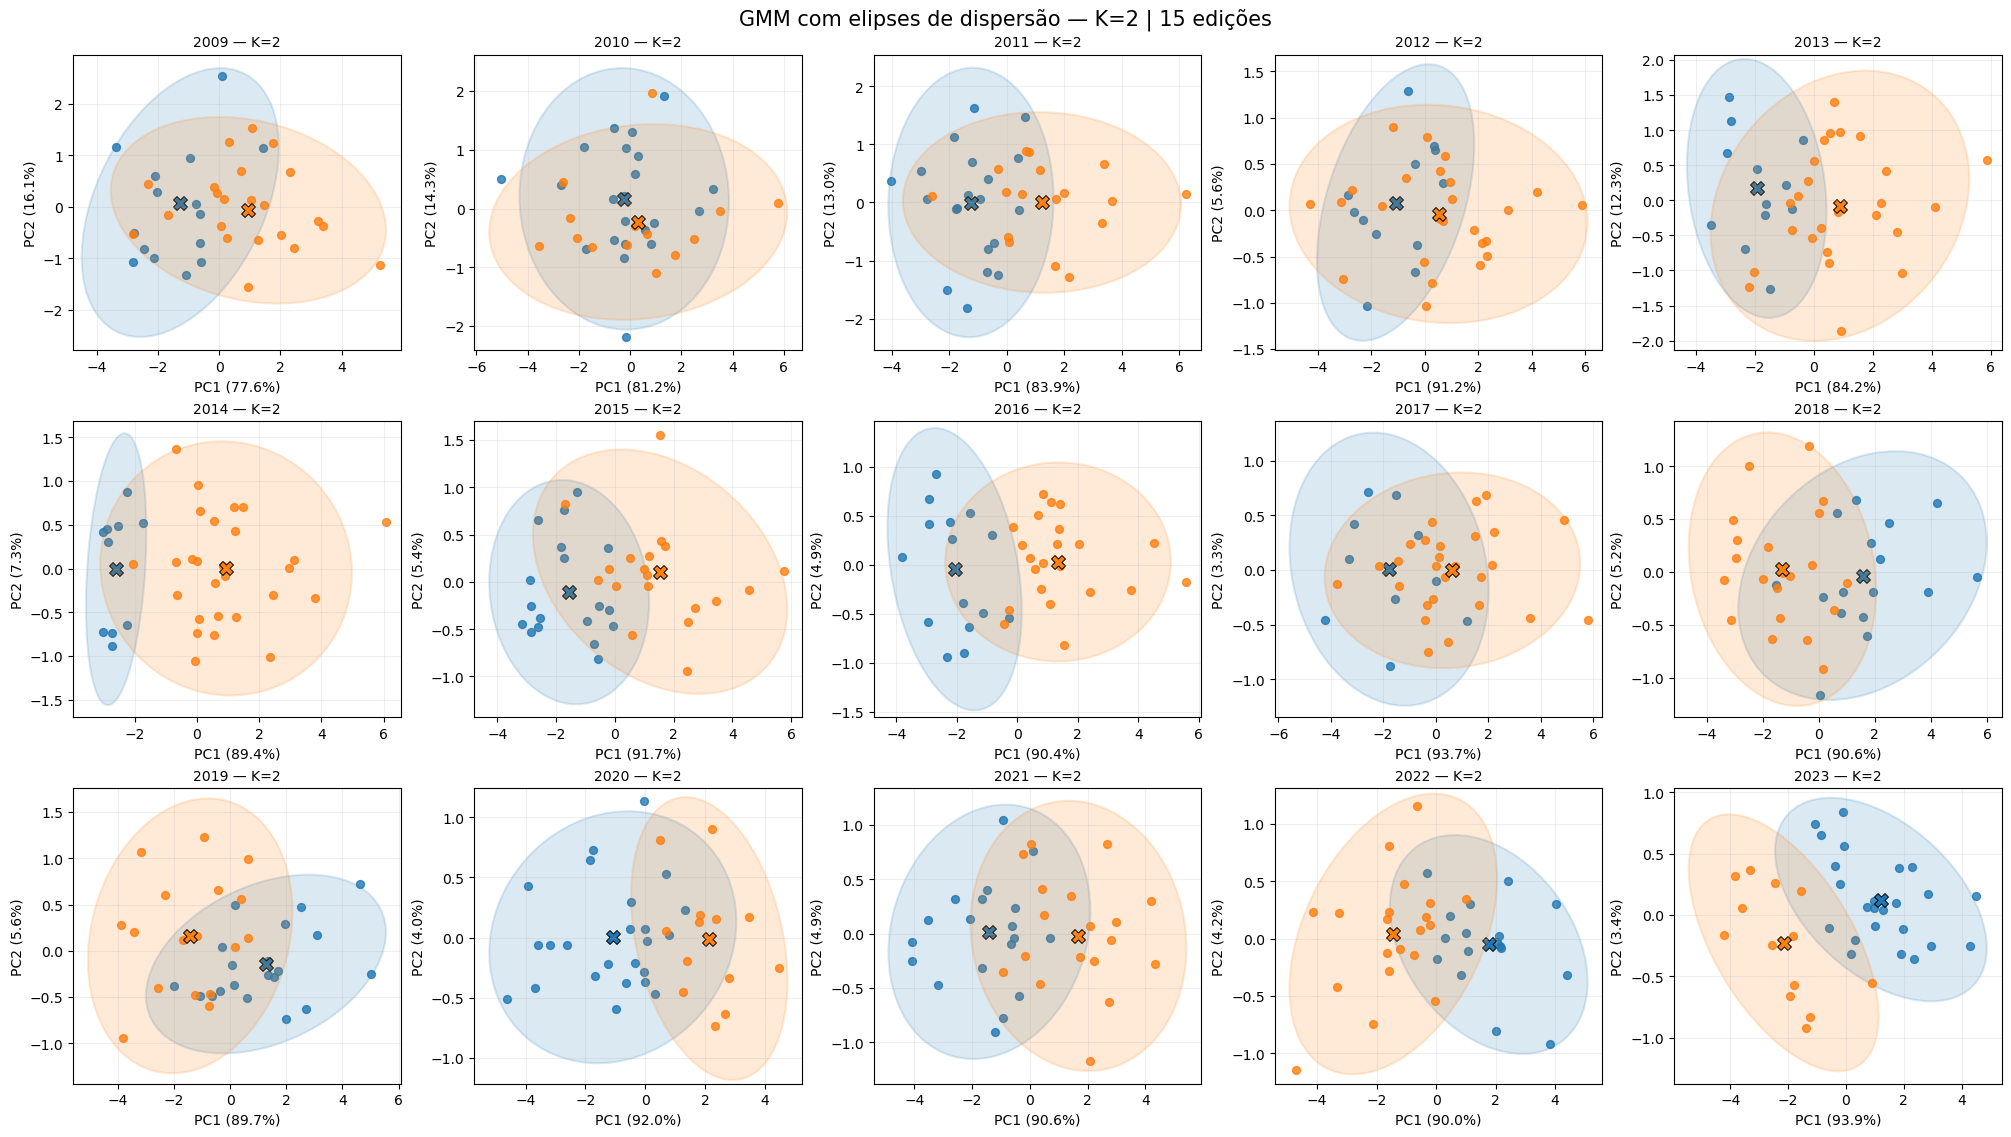

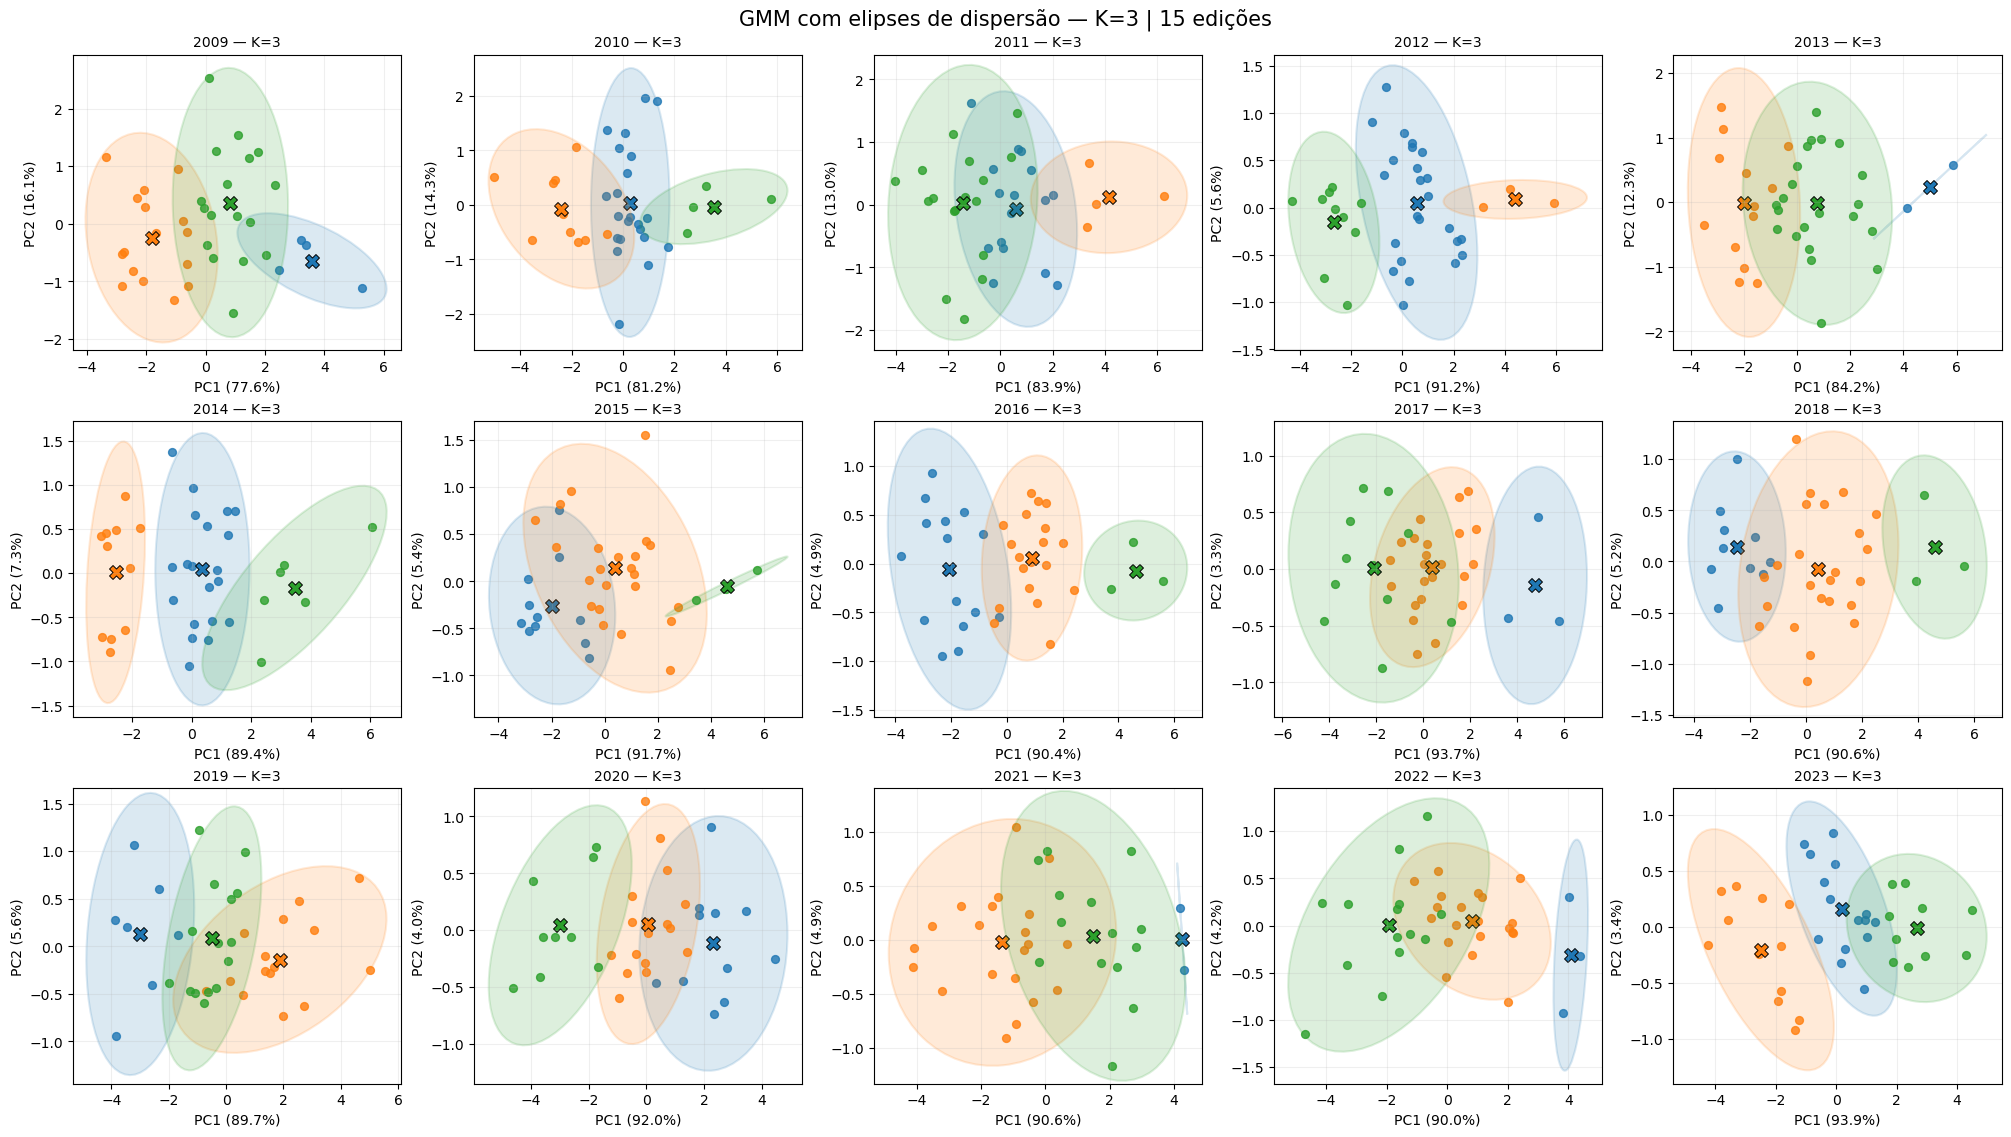

In [5]:
from matplotlib.patches import Ellipse
from sklearn.decomposition import PCA
from scipy.stats import chi2

# Escala da elipse para conter aproximadamente 95% da distribuição em 2D.
FATOR_ELIPSE_95 = np.sqrt(chi2.ppf(0.95, df=2))


def adicionar_elipse_gaussiana(ax, centro, covariancia, cor, fator=FATOR_ELIPSE_95):
    """Desenha a elipse de dispersão de uma gaussiana bidimensional."""
    valores, vetores = np.linalg.eigh(covariancia)
    ordem = np.argsort(valores)[::-1]
    valores = np.maximum(valores[ordem], 0)
    vetores = vetores[:, ordem]

    angulo = np.degrees(np.arctan2(vetores[1, 0], vetores[0, 0]))
    largura, altura = 2 * fator * np.sqrt(valores)
    elipse = Ellipse(
        xy=centro, width=largura, height=altura, angle=angulo,
        facecolor=cor, edgecolor=cor, alpha=0.16, linewidth=1.5
    )
    ax.add_patch(elipse)


def plotar_gmm_elipses_por_ano(k):
    fig, axes = plt.subplots(3, 5, figsize=(20, 11), constrained_layout=True)
    axes = axes.ravel()

    for ax, ano in zip(axes, ANOS):
        grupo = (
            painel_coorte.loc[painel_coorte["ano"].eq(ano)]
            .sort_values("CO_MUNICIPIO_TERRITORIO")
            .copy()
        )
        X = grupo[DISCIPLINAS].astype(float).to_numpy()
        X_scaled = StandardScaler().fit_transform(X)

        # Ajuste do GMM nas cinco disciplinas padronizadas.
        modelo = GaussianMixture(
            n_components=k, covariance_type="full",
            random_state=RANDOM_STATE, n_init=5, reg_covar=1e-6
        )
        labels = modelo.fit_predict(X_scaled)

        # PCA serve apenas para projetar os dados e as gaussianas em 2D.
        pca = PCA(n_components=2)
        pontos_2d = pca.fit_transform(X_scaled)
        centros_2d = pca.transform(modelo.means_)
        componentes = pca.components_

        cores = plt.get_cmap("tab10").colors
        for componente in range(k):
            mascara = labels == componente
            cor = cores[componente]
            ax.scatter(
                pontos_2d[mascara, 0], pontos_2d[mascara, 1],
                s=32, color=cor, alpha=0.8,
                label=f"Componente {componente + 1}"
            )

            # Projeta a matriz de covariância 5D para o plano das duas PCs.
            cov_5d = modelo.covariances_[componente]
            cov_2d = componentes @ cov_5d @ componentes.T
            adicionar_elipse_gaussiana(
                ax, centros_2d[componente], cov_2d, cor
            )
            ax.scatter(
                centros_2d[componente, 0], centros_2d[componente, 1],
                marker="X", s=100, color=cor, edgecolor="black", linewidth=0.7
            )

        variancia = pca.explained_variance_ratio_ * 100
        ax.set_title(f"{ano} — K={k}", fontsize=10)
        ax.set_xlabel(f"PC1 ({variancia[0]:.1f}%)")
        ax.set_ylabel(f"PC2 ({variancia[1]:.1f}%)")
        ax.grid(alpha=0.2)

    fig.suptitle(
        f"GMM com elipses de dispersão — K={k} | 15 edições",
        fontsize=15, y=1.02
    )
    plt.show()


plotar_gmm_elipses_por_ano(k=2)
plotar_gmm_elipses_por_ano(k=3)


## 7. DBSCAN — busca exploratória de parâmetros

O DBSCAN não recebe o número de clusters. Seus resultados dependem de `eps` (raio da vizinhança) e `min_samples` (quantidade mínima de observações para formar uma região densa).

Serão testadas combinações moderadas desses parâmetros. Não será escolhido automaticamente um vencedor: a tabela permitirá observar quantos grupos surgem, quantos municípios ficam como ruído e se as métricas são calculáveis. Uma configuração que classifique quase todos os municípios como ruído ou forme apenas um grupo não será considerada uma solução útil para este objetivo.

In [6]:
DBSCAN_EPS = [0.8, 1.0, 1.2, 1.5, 1.8, 2.0, 2.5]
DBSCAN_MIN_SAMPLES = [4, 5, 6]

resultados_dbscan = []
classificacoes_dbscan = []

for ano in ANOS:
    grupo = (
        painel_coorte.loc[painel_coorte["ano"].eq(ano)]
        .sort_values("CO_MUNICIPIO_TERRITORIO")
        .copy()
    )
    X_scaled = StandardScaler().fit_transform(grupo[DISCIPLINAS].astype(float))
    ids = grupo["CO_MUNICIPIO_TERRITORIO"].to_numpy()
    base_ano = (
        kmeans_base.loc[kmeans_base["ano"].eq(ano)]
        .set_index("CO_MUNICIPIO_TERRITORIO")
        .loc[ids]
    )
    labels_kmeans = base_ano["cluster_original"].to_numpy()

    for eps in DBSCAN_EPS:
        for min_samples in DBSCAN_MIN_SAMPLES:
            labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
            mask = labels != -1
            labels_validos = labels[mask]
            X_validos = X_scaled[mask]
            n_grupos = len(set(labels_validos))
            n_ruido = int((~mask).sum())
            metricas = calcular_metricas(X_validos, labels_validos) if mask.sum() else {
                "silhouette": np.nan, "calinski_harabasz": np.nan, "davies_bouldin": np.nan
            }
            ari = (
                adjusted_rand_score(labels_kmeans[mask], labels_validos)
                if n_grupos >= 2 and mask.sum() >= 2 else np.nan
            )
            tamanhos = pd.Series(labels_validos).value_counts() if mask.sum() else pd.Series(dtype=int)

            resultados_dbscan.append({
                "ano": ano, "eps": eps, "min_samples": min_samples,
                "n_grupos": n_grupos, "n_ruido": n_ruido,
                "perc_ruido": n_ruido / len(grupo) * 100,
                "menor_grupo": int(tamanhos.min()) if len(tamanhos) else 0,
                "maior_grupo": int(tamanhos.max()) if len(tamanhos) else 0,
                "silhouette": metricas["silhouette"],
                "calinski_harabasz": metricas["calinski_harabasz"],
                "davies_bouldin": metricas["davies_bouldin"],
                "ari_vs_kmeans_classificados": ari,
            })

            for municipio, label in zip(ids, labels):
                classificacoes_dbscan.append({
                    "ano": ano, "CO_MUNICIPIO_TERRITORIO": municipio,
                    "eps": eps, "min_samples": min_samples,
                    "cluster": int(label),
                    "status": "Ruído" if label == -1 else "Agrupado",
                })

resultados_dbscan = pd.DataFrame(resultados_dbscan)
classificacoes_dbscan = pd.DataFrame(classificacoes_dbscan)

resumo_dbscan = (
    resultados_dbscan.groupby(["eps", "min_samples"])
    .agg(
        anos_avaliados=("ano", "nunique"),
        grupos_medios=("n_grupos", "mean"),
        ruido_medio_pct=("perc_ruido", "mean"),
        silhouette_media=("silhouette", "mean"),
        davies_bouldin_medio=("davies_bouldin", "mean"),
        ari_medio_vs_kmeans=("ari_vs_kmeans_classificados", "mean"),
    ).reset_index()
)
display(resumo_dbscan.round(3))

,eps,min_samples,anos_avaliados,grupos_medios,ruido_medio_pct,silhouette_media,davies_bouldin_medio,ari_medio_vs_kmeans
0,0.8,4,15,2.533,46.667,0.496,0.658,0.485
1,0.8,5,15,2.000,59.640,0.484,0.668,0.528
2,0.8,6,15,1.067,75.856,0.452,0.746,0.449
3,1.0,4,15,1.933,19.820,0.434,0.669,0.252
4,1.0,5,15,1.733,29.910,0.469,0.649,0.446
5,1.0,6,15,1.733,35.676,0.485,0.628,0.502
6,1.2,4,15,1.333,11.532,0.467,0.619,0.421
7,1.2,5,15,1.267,15.856,0.476,0.640,0.583
8,1.2,6,15,1.133,21.802,0.503,0.634,0.402
9,1.5,4,15,1.000,4.324,NaN,NaN,NaN


## 8. Comparação direta com o K-Means original

A comparação mais importante para a decisão não é apenas qual algoritmo apresenta a maior métrica interna, mas **quanto a classificação municipal muda em relação ao K-Means já utilizado**.

Para Agglomerative e GMM, o ARI considera todos os 37 municípios. Para DBSCAN, o ARI considera apenas os municípios que não foram classificados como ruído; por isso, deve ser lido junto com a porcentagem de ruído.

,algoritmo,k,ari_medio,ari_mediano,ari_minimo,ari_maximo,silhouette_media
0,Agglomerative,2,0.633,0.690,0.019,1.000,0.460
1,Agglomerative,3,0.439,0.405,0.084,0.795,0.435
2,GMM,2,0.339,0.307,-0.041,0.694,0.288
3,GMM,3,0.392,0.374,0.060,0.795,0.369


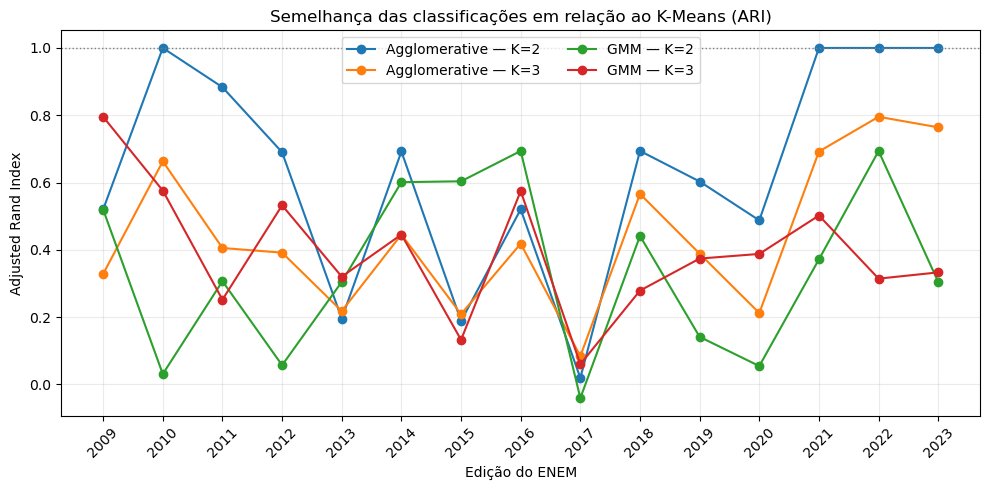

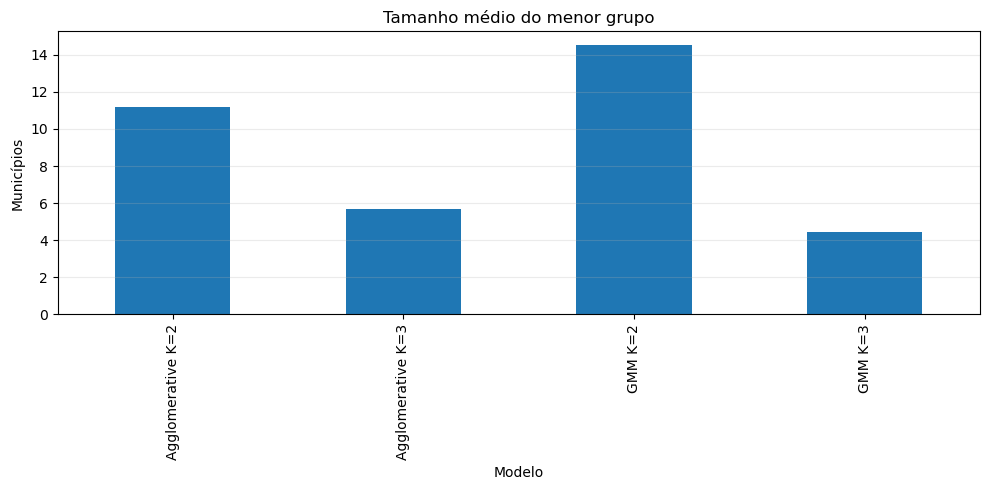

In [7]:
# Resumo dos algoritmos com K definido, incluindo a distribuição do ARI por ano.
comparacao_ari = (
    resultados_fixos.groupby(["algoritmo", "k"])
    .agg(
        ari_medio=("ari_vs_kmeans", "mean"),
        ari_mediano=("ari_vs_kmeans", "median"),
        ari_minimo=("ari_vs_kmeans", "min"),
        ari_maximo=("ari_vs_kmeans", "max"),
        silhouette_media=("silhouette", "mean"),
    ).reset_index()
)
display(comparacao_ari.round(3))

fig, ax = plt.subplots(figsize=(10, 5))
for (algoritmo, k), dados in resultados_fixos.groupby(["algoritmo", "k"]):
    ax.plot(dados["ano"], dados["ari_vs_kmeans"], marker="o", label=f"{algoritmo} — K={k}")
ax.axhline(1, color="gray", linestyle=":", linewidth=1)
ax.set(
    title="Semelhança das classificações em relação ao K-Means (ARI)",
    xlabel="Edição do ENEM", ylabel="Adjusted Rand Index"
)
ax.set_xticks(ANOS)
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.25)
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

# Distribuição dos tamanhos dos grupos por algoritmo e K.
fig, ax = plt.subplots(figsize=(10, 5))
resumo_fixos.set_index(resumo_fixos["algoritmo"] + " K=" + resumo_fixos["k"].astype(str))[
    "menor_grupo_medio"
].plot(kind="bar", ax=ax)
ax.set(title="Tamanho médio do menor grupo", xlabel="Modelo", ylabel="Municípios")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 9. Comparação da composição dos perfis

O ARI resume a concordância global, mas não mostra quais municípios mudaram de grupo. A tabela seguinte apresenta, por ano, a concordância simples entre os perfis A/B do K-Means e os perfis A/B dos modelos alternativos. Os rótulos A/B são recalculados em cada edição pela média geral dos municípios em cada grupo; isso permite comparar o sentido dos perfis, e não os números arbitrários dos clusters.

In [8]:
# Converter os rótulos originais do K-Means em Perfil A/B pela mesma regra usada no estudo.
perfis_kmeans = []
for ano in ANOS:
    grupo = (
        painel_coorte.loc[painel_coorte["ano"].eq(ano)]
        .sort_values("CO_MUNICIPIO_TERRITORIO")
        .copy()
    )
    base = (
        kmeans_base.loc[kmeans_base["ano"].eq(ano)]
        .set_index("CO_MUNICIPIO_TERRITORIO")
        .loc[grupo["CO_MUNICIPIO_TERRITORIO"]]
    )
    perfis = rotulos_perfil_por_media(grupo, base["cluster_original"].to_numpy())
    for municipio, perfil in zip(grupo["CO_MUNICIPIO_TERRITORIO"], perfis):
        perfis_kmeans.append({"ano": ano, "CO_MUNICIPIO_TERRITORIO": municipio, "perfil_kmeans": f"Perfil {perfil}"})
perfis_kmeans = pd.DataFrame(perfis_kmeans)

comparacao_perfis = classificacoes_fixos.merge(
    perfis_kmeans, on=["ano", "CO_MUNICIPIO_TERRITORIO"], how="left"
)
comparacao_perfis["concorda_perfil"] = (
    comparacao_perfis["perfil_relativo"] == comparacao_perfis["perfil_kmeans"]
)
resumo_concordancia = (
    comparacao_perfis.groupby(["algoritmo", "k"])
    .agg(
        concordancia_media_pct=("concorda_perfil", lambda x: x.mean() * 100),
        concordancia_min_pct=("concorda_perfil", lambda x: x.groupby(comparacao_perfis.loc[x.index, "ano"]).mean().min() * 100),
        concordancia_max_pct=("concorda_perfil", lambda x: x.groupby(comparacao_perfis.loc[x.index, "ano"]).mean().max() * 100),
    ).reset_index()
)
display(resumo_concordancia.round(1))

# Municípios que mudam de perfil em uma edição selecionada podem ser inspecionados aqui.
ANO_INSPECAO = 2023
tabela_inspecao = (
    comparacao_perfis.loc[comparacao_perfis["ano"].eq(ANO_INSPECAO)]
    .pivot_table(
        index="CO_MUNICIPIO_TERRITORIO", columns=["algoritmo", "k"],
        values="perfil_relativo", aggfunc="first"
    ).reset_index()
)
tabela_inspecao.columns = [
    "CO_MUNICIPIO_TERRITORIO" if not isinstance(col, tuple) or col[0] == "CO_MUNICIPIO_TERRITORIO"
    else f"{col[0]}_K{int(col[1])}"
    for col in tabela_inspecao.columns
]
tabela_inspecao = tabela_inspecao.merge(
    perfis_kmeans.loc[perfis_kmeans["ano"].eq(ANO_INSPECAO),
                      ["CO_MUNICIPIO_TERRITORIO", "perfil_kmeans"]],
    on="CO_MUNICIPIO_TERRITORIO", how="left", validate="one_to_one"
)
display(tabela_inspecao)

,algoritmo,k,concordancia_media_pct,concordancia_min_pct,concordancia_max_pct
0,Agglomerative,2,88.6,62.2,100.0
1,Agglomerative,3,52.4,10.8,86.5
2,GMM,2,76.0,37.8,91.9
3,GMM,3,68.8,24.3,89.2


,CO_MUNICIPIO_TERRITORIO,Agglomerative_K2,Agglomerative_K3,GMM_K2,GMM_K3,perfil_kmeans
0,1500107,Perfil B,Perfil C,Perfil B,Perfil B,Perfil B
1,1500404,Perfil A,Perfil A,Perfil A,Perfil A,Perfil A
2,1500602,Perfil B,Perfil C,Perfil B,Perfil C,Perfil B
3,1500800,Perfil B,Perfil C,Perfil B,Perfil C,Perfil B
4,1501303,Perfil B,Perfil C,Perfil B,Perfil B,Perfil B
5,1501402,Perfil B,Perfil C,Perfil B,Perfil C,Perfil B
6,1501501,Perfil B,Perfil C,Perfil A,Perfil B,Perfil B
7,1501709,Perfil B,Perfil C,Perfil B,Perfil B,Perfil B
8,1501808,Perfil A,Perfil B,Perfil A,Perfil A,Perfil A
9,1502103,Perfil A,Perfil B,Perfil B,Perfil B,Perfil A


## 10. Diagnóstico do DBSCAN

O DBSCAN deve ser interpretado de forma diferente dos modelos com K definido. Uma configuração pode apresentar Silhouette alta apenas porque excluiu muitos municípios como ruído. Por isso, observe conjuntamente: número médio de grupos, percentual médio de ruído, métricas internas e ARI. Se a maior parte dos municípios for classificada como ruído, a solução não é adequada para formar perfis comparáveis de todos os municípios.

In [9]:
# Mostrar configurações DBSCAN que, em média, formaram pelo menos dois grupos
# e classificaram pelo menos 70% dos municípios como pertencentes a grupos.
dbscan_candidatos = resumo_dbscan.loc[
    (resumo_dbscan["grupos_medios"] >= 2)
    & (resumo_dbscan["ruido_medio_pct"] <= 30)
].sort_values(
    ["ruido_medio_pct", "silhouette_media"], ascending=[True, False]
)
display(dbscan_candidatos.round(3))

print("Configurações avaliadas:", len(resumo_dbscan))
print("Configurações com ≥2 grupos em média e ≤30% de ruído:", len(dbscan_candidatos))
if dbscan_candidatos.empty:
    print("Nenhuma configuração satisfez simultaneamente os critérios exploratórios definidos.")

,eps,min_samples,anos_avaliados,grupos_medios,ruido_medio_pct,silhouette_media,davies_bouldin_medio,ari_medio_vs_kmeans


Configurações avaliadas: 21
Configurações com ≥2 grupos em média e ≤30% de ruído: 0
Nenhuma configuração satisfez simultaneamente os critérios exploratórios definidos.


## 11. Síntese comparativa e critérios para decisão

A decisão sobre manter ou substituir o K-Means deve considerar quatro dimensões:

1. **Diferença na composição:** ARI e concordância dos perfis em relação ao K-Means.
2. **Qualidade interna:** Silhouette, Davies-Bouldin e Calinski-Harabasz, sem tratar uma métrica isolada como verdade absoluta.
3. **Equilíbrio e interpretabilidade:** tamanho dos grupos e existência de grupos muito pequenos.
4. **Cobertura:** especialmente no DBSCAN, proporção de municípios classificados como ruído.

### Orientação de leitura

- Se Agglomerative ou GMM apresentarem ARI elevado e perfis semelhantes, isso reforça a robustez da solução atual do K-Means.
- Se apresentarem diferenças consistentes e grupos interpretáveis, vale investigar a alternativa antes de alterar o modelo definitivo.
- Se DBSCAN produzir muito ruído ou número instável de grupos, isso indica que uma abordagem baseada em densidade pode não ser adequada para esta amostra pequena (37 municípios por edição).
- Não comparar diretamente o valor de Silhouette de modelos calculados sobre amostras diferentes. No DBSCAN, registrar sempre a cobertura usada no cálculo.

**Este notebook não escolhe automaticamente um algoritmo definitivo.** A escolha será feita após a leitura conjunta das tabelas, dos gráficos e da interpretação substantiva dos municípios.

In [10]:
# Resumo consolidado para facilitar a decisão final.
resumo_decisao = resumo_fixos.copy()
resumo_decisao["tipo_modelo"] = "K definido"

resumo_dbscan_decisao = resumo_dbscan.copy()
resumo_dbscan_decisao["tipo_modelo"] = "Densidade"
resumo_dbscan_decisao["algoritmo"] = "DBSCAN"
resumo_dbscan_decisao["k"] = np.nan
resumo_dbscan_decisao = resumo_dbscan_decisao.rename(columns={
    "grupos_medios": "n_grupos_medio",
    "ruido_medio_pct": "ruido_medio_pct",
    "ari_medio_vs_kmeans": "ari_medio_vs_kmeans",
})

print("Resumo Agglomerative/GMM:")
display(resumo_decisao.round(3))
print("Resumo DBSCAN — todas as configurações:")
display(resumo_dbscan_decisao.round(3))

Resumo Agglomerative/GMM:


,algoritmo,k,anos_avaliados,silhouette_media,calinski_harabasz_medio,davies_bouldin_medio,ari_medio_vs_kmeans,menor_grupo_medio,tipo_modelo
0,Agglomerative,2,15,0.460,40.706,0.691,0.633,11.200,K definido
1,Agglomerative,3,15,0.435,50.758,0.732,0.439,5.667,K definido
2,GMM,2,15,0.288,25.724,1.339,0.339,14.533,K definido
3,GMM,3,15,0.369,40.338,0.772,0.392,4.467,K definido


Resumo DBSCAN — todas as configurações:


,eps,min_samples,anos_avaliados,n_grupos_medio,ruido_medio_pct,silhouette_media,davies_bouldin_medio,ari_medio_vs_kmeans,tipo_modelo,algoritmo,k
0,0.8,4,15,2.533,46.667,0.496,0.658,0.485,Densidade,DBSCAN,NaN
1,0.8,5,15,2.000,59.640,0.484,0.668,0.528,Densidade,DBSCAN,NaN
2,0.8,6,15,1.067,75.856,0.452,0.746,0.449,Densidade,DBSCAN,NaN
3,1.0,4,15,1.933,19.820,0.434,0.669,0.252,Densidade,DBSCAN,NaN
4,1.0,5,15,1.733,29.910,0.469,0.649,0.446,Densidade,DBSCAN,NaN
5,1.0,6,15,1.733,35.676,0.485,0.628,0.502,Densidade,DBSCAN,NaN
6,1.2,4,15,1.333,11.532,0.467,0.619,0.421,Densidade,DBSCAN,NaN
7,1.2,5,15,1.267,15.856,0.476,0.640,0.583,Densidade,DBSCAN,NaN
8,1.2,6,15,1.133,21.802,0.503,0.634,0.402,Densidade,DBSCAN,NaN
9,1.5,4,15,1.000,4.324,NaN,NaN,NaN,Densidade,DBSCAN,NaN


## 12. Exportação dos resultados

Os arquivos são salvos em uma subpasta `comparacao_algoritmos` dentro do diretório de resultados do estudo. Assim, os resultados experimentais ficam separados dos arquivos oficiais produzidos pelo notebook principal.

In [11]:
DIRETORIO_COMPARACAO = DIRETORIO_RESULTADOS / "comparacao_algoritmos"
DIRETORIO_COMPARACAO.mkdir(parents=True, exist_ok=True)

saidas = {
    "metricas_agglomerative_gmm_por_ano.csv": resultados_fixos,
    "resumo_agglomerative_gmm.csv": resumo_fixos,
    "classificacoes_agglomerative_gmm.csv": classificacoes_fixos,
    "metricas_dbscan_por_ano.csv": resultados_dbscan,
    "resumo_dbscan.csv": resumo_dbscan,
    "classificacoes_dbscan.csv": classificacoes_dbscan,
    "comparacao_perfis_vs_kmeans.csv": comparacao_perfis,
    "resumo_concordancia_perfis.csv": resumo_concordancia,
}

for nome, tabela in saidas.items():
    tabela.to_csv(DIRETORIO_COMPARACAO / nome, index=False, sep=";", encoding="utf-8-sig")

print("Arquivos exportados em:", DIRETORIO_COMPARACAO.resolve())
for nome in saidas:
    print("-", nome)

Arquivos exportados em: /home/akel/PycharmProjects/Projeto_ENEM/data/reports/evolucao_temporal_municipal/uf=PA/ref=ESC/comparacao_algoritmos
- metricas_agglomerative_gmm_por_ano.csv
- resumo_agglomerative_gmm.csv
- classificacoes_agglomerative_gmm.csv
- metricas_dbscan_por_ano.csv
- resumo_dbscan.csv
- classificacoes_dbscan.csv
- comparacao_perfis_vs_kmeans.csv
- resumo_concordancia_perfis.csv


## 13. Conclusão do experimento

Preencher esta seção após executar todas as células. A conclusão deve responder objetivamente:

- Agglomerative e GMM reproduziram os perfis do K-Means ou alteraram significativamente a composição dos grupos?
- As diferenças foram consistentes ao longo das 15 edições ou concentradas em alguns anos?
- O DBSCAN encontrou grupos úteis sem excluir uma parcela excessiva dos municípios?
- Algum algoritmo apresentou ganhos claros de qualidade e interpretabilidade que justifiquem substituir o K-Means?

**Regra de decisão:** só recomendar a substituição do K-Means se a alternativa apresentar melhoria consistente nos diagnósticos, composição municipal interpretável e maior adequação ao objetivo longitudinal. Caso contrário, manter o K-Means como modelo principal e registrar a comparação como análise de robustez.